# iTracer

The lineage-recorded iTracer hindbrain organoid dataset (He et al., 2022), with the middle diffusion-pseudotime tertile withheld. We construct transition kernels from expression alone and augment them with RNA velocity, lineage similarity from barcode and scar families, or both; the RNA velocity, transition graph, and derived geometric quantities are recomputed after removing the evaluation cells. The tuned points were selected before this refit, when the velocity moments still used the all-cell neighbour graph restricted to the shown cells, and are reused without retuning.

Reproduces the iTracer rows of Table 2.

In [1]:
import pathlib
import sys

ROOT = next(p for p in (pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents)
            if (p / "ffm").is_dir() and (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT))

from scripts.itracer import paper

paper.ensure()

## Dataset

2,901 lineage-recorded cells of the hindbrain organoid on their UMAP. $p_0$ and $p_1$ are the early and late diffusion-pseudotime tertiles, and the middle tertile is withheld; 867 of its 967 cells are scored and the remaining 100 are used for tuning.

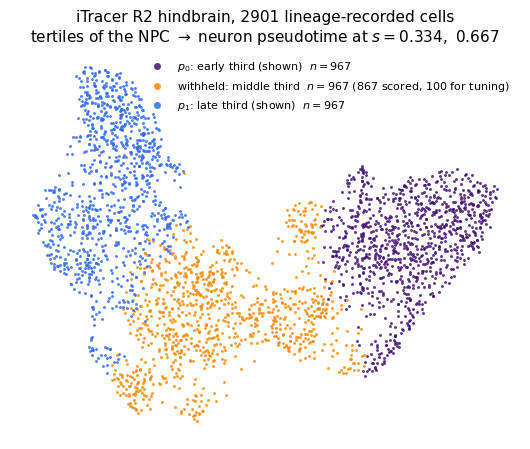

In [2]:
paper.figure_dataset()

## Midpoint and endpoint $W_2$

Midpoint $W_2$ compares the flow at $t = 1/2$ with the 867 withheld cells not used for tuning, and endpoint $W_2$ compares $t = 1$ with the target; mean ± population SD over five seeds. The sampling floor is the empirical Wasserstein distance between two disjoint halves of the corresponding reference population.

In [3]:
paper.mid_end()

d = 20                     d = 50  \
                                mid W2       end W2        mid W2   
Method                                                              
OT-CFM                    15.86 ± 0.10  5.78 ± 0.04  18.90 ± 0.15   
MFM / LAND                14.95 ± 0.17  6.71 ± 0.24  18.24 ± 0.12   
Curly-FM                  15.83 ± 0.36  6.34 ± 0.05  18.95 ± 0.29   
FFM, expression           12.85 ± 0.07  6.20 ± 0.07  16.76 ± 0.21   
FFM + velocity            12.77 ± 0.11  6.25 ± 0.16  16.80 ± 0.21   
FFM + lineage             12.76 ± 0.10  6.33 ± 0.21  16.84 ± 0.20   
FFM + velocity + lineage  12.74 ± 0.07  6.23 ± 0.20  16.94 ± 0.16   
sampling floor                    7.35         5.64         11.45   

                                        
                                end W2  
Method                                  
OT-CFM                    11.10 ± 0.09  
MFM / LAND                11.54 ± 0.04  
Curly-FM                  11.44 ± 0.21  
FFM, expression           11.40 ± 0.17  
FFM + velocity            11.32 ± 0.09  
FFM + lineage             11.43 ± 0.10  
FFM + velocity + lineage  11.34 ± 0.14  
sampling floor                   10.12

## State interpolation (Table 2, iTracer)

Midpoint $W_2$ for kernels built from expression alone ($\beta_{\mathrm{lin}} = \nu = 0$) and augmented with RNA velocity ($\nu = 3$), lineage similarity ($\beta_{\mathrm{lin}} = 3$), or both. All FFM variants achieve lower midpoint $W_2$ than OT-CFM, MFM, and Curly-FM, although the best-performing kernel depends on dimensionality.

In [4]:
paper.table2()

,d = 20,d = 50
Method,,
OT-CFM,15.86 ± 0.10,18.90 ± 0.15
MFM / LAND,14.95 ± 0.17,18.24 ± 0.12
Curly-FM,15.83 ± 0.36,18.95 ± 0.29
"FFM, expression",12.85 ± 0.07,16.76 ± 0.21
FFM + velocity,12.77 ± 0.11,16.80 ± 0.21
FFM + lineage,12.76 ± 0.10,16.84 ± 0.20
FFM + velocity + lineage,12.74 ± 0.07,16.94 ± 0.16
